# Inflación en Argentina, 2017-2026

Análisis de la inflación mensual e interanual en Argentina usando el IPC nivel general nacional (base dic 2016) del INDEC.

**Fuente de datos:** API de series de tiempo del Gobierno argentino (datos.gob.ar), serie `148.3_INIVELNAL_DICI_M_26`.

**Pregunta:** ¿cómo evolucionó la inflación en Argentina en los últimos 9 años y qué tan fuerte fue el pico de 2023-2024?

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

## Inflación mensual

La API devuelve la variación porcentual mensual del IPC nivel general nacional (índice con base 100 en diciembre de 2016). La serie cubre 116 meses, de enero de 2017 a agosto de 2026, sin meses faltantes.

El pico se dio en diciembre de 2023, con una inflación de 25,5% en un solo mes.

In [ ]:
from io import StringIO
import pandas as pd
import requests

# Descarga desde la API oficial
url = "https://apis.datos.gob.ar/series/api/series/"
parametros = {
    "ids": "148.3_INIVELNAL_DICI_M_26",
    "representation_mode": "percent_change",  # Devuelve la variación mensual
    "format": "csv",
    "start_date": "2016-12-01",  # Un mes antes, para conservar enero 2017
    "limit": 1000,
}

r = requests.get(url, params=parametros)
ipc = pd.read_csv(StringIO(r.text))
ipc.columns = ["fecha", "inflacion_mensual"]

# Formato de fecha y conversión a porcentaje (%)
ipc["fecha"] = pd.to_datetime(ipc["fecha"])
ipc = ipc.sort_values("fecha").dropna().reset_index(drop=True)
ipc["inflacion_mensual"] = ipc["inflacion_mensual"] * 100

# 3. Chequeo cuántos meses hay y si falta alguno en el medio
print("Cantidad de meses:", len(ipc))
saltos = ipc["fecha"].diff().dt.days.dropna()
print("Meses salteados:", int((saltos > 31).sum()))

# Mostrar primeros 5 y últimos 5 meses
print("\n--- PRIMEROS 5 MESES DE LA SERIE ---")
print(ipc.head(5).to_string(index=False))

print("\n--- ÚLTIMOS 5 MESES DE LA SERIE ---")
print(ipc.tail(5).to_string(index=False))

# Guardar los datos procesados para usarlos en los gráficos
ipc.to_csv("inflacion_mensual.csv", index=False)

Cantidad de meses: 116
Meses salteados: 0

--- PRIMEROS 5 MESES DE LA SERIE ---
     fecha  inflacion_mensual
2017-01-01           1.585900
2017-02-01           2.067216
2017-03-01           2.374190
2017-04-01           2.655830
2017-05-01           1.434750

--- ÚLTIMOS 5 MESES DE LA SERIE ---
     fecha  inflacion_mensual
2026-04-01           2.582180
2026-05-01           2.149972
2026-06-01           1.886871
2026-07-01           2.113772
2026-08-01           1.659206



Pico máximo de inflación: Diciembre 2023 con 25.5% de inflación mensual



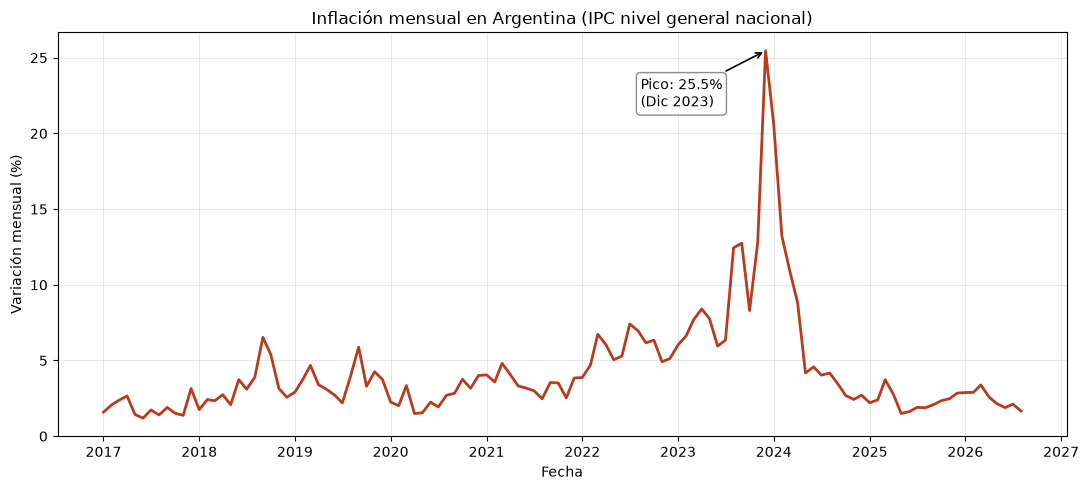

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Leer los datos guardados
ipc = pd.read_csv("inflacion_mensual.csv")
ipc["fecha"] = pd.to_datetime(ipc["fecha"])

# Detectar el pico máximo
max_idx = ipc["inflacion_mensual"].idxmax()
max_row = ipc.loc[max_idx]
max_fecha = max_row["fecha"]
max_val = max_row["inflacion_mensual"]

# Mapeo de meses a español
meses_es = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre",
}
mes_nombre = meses_es[max_fecha.month]

# Texto informativo antes del gráfico
print("\n" + "=" * 65)
print(
    f"Pico máximo de inflación: {mes_nombre} {max_fecha.year} con {max_val:.1f}% de inflación mensual"
)
print("=" * 65 + "\n")

# Armar el gráfico
plt.figure(figsize=(11, 5))
plt.plot(ipc["fecha"], ipc["inflacion_mensual"], color="#b83b1d", linewidth=2)

# Anotación en el pico máximo
plt.annotate(
    f"Pico: {max_val:.1f}%\n({mes_nombre[:3]} {max_fecha.year})",
    xy=(max_fecha, max_val),
    xytext=(-90, -40),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
)

plt.title("Inflación mensual en Argentina (IPC nivel general nacional)")
plt.xlabel("Fecha")
plt.ylabel("Variación mensual (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Mostrar gráfico
plt.show()

## Inflación interanual

La variación interanual compara cada mes con el mismo mes del año anterior. Se calcula acumulando las variaciones mensuales de 12 meses móviles. Suaviza los saltos mensuales y es la medida más usada en informes económicos.

El máximo se alcanzó en abril de 2024, con 289,4% interanual. Desde entonces la inflación interanual bajó fuerte y se estabilizó en torno al 30-35% en 2025 y 2026.


Pico máximo de inflación interanual: Abril 2024 con 289.4% interanual



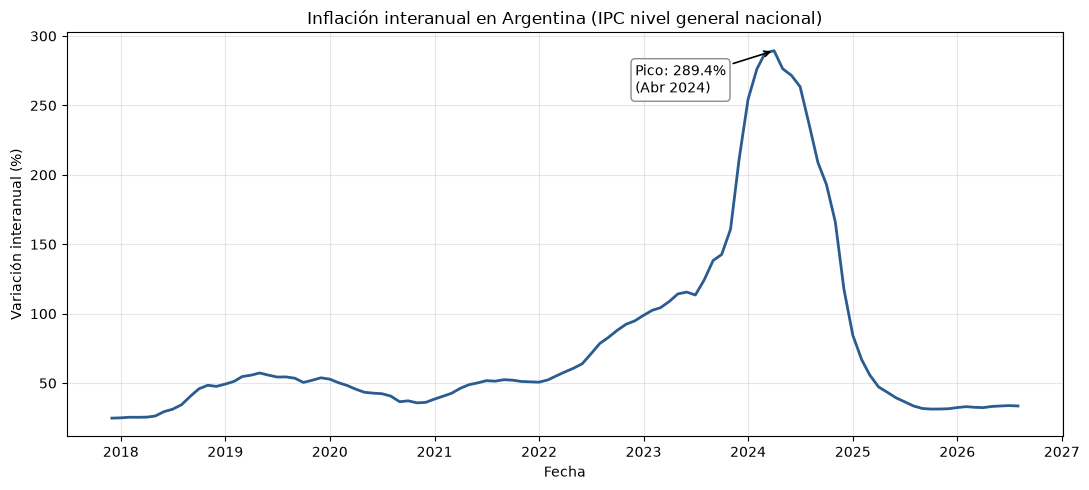

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Leer los datos mensuales ya descargados
ipc = pd.read_csv("inflacion_mensual.csv")
ipc["fecha"] = pd.to_datetime(ipc["fecha"])

# Calcular la inflación interanual (acumulado de 12 meses móviles)
ipc["inflacion_interanual"] = (
    (1 + ipc["inflacion_mensual"] / 100).rolling(12).apply(np.prod, raw=True) - 1
) * 100

# Eliminamos los primeros 11 meses que quedan vacíos al no tener 12 meses hacia atrás
ipc_interanual = ipc.dropna(subset=["inflacion_interanual"]).reset_index(
    drop=True
)

# 3. Detectar el pico máximo interanual
max_idx = ipc_interanual["inflacion_interanual"].idxmax()
max_row = ipc_interanual.loc[max_idx]
max_fecha = max_row["fecha"]
max_val = max_row["inflacion_interanual"]

# Mapeo de meses a español
meses_es = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre",
}
mes_nombre = meses_es[max_fecha.month]

# Texto informativo antes del gráfico
print("\n" + "=" * 68)
print(
    f"Pico máximo de inflación interanual: {mes_nombre} {max_fecha.year} con {max_val:.1f}% interanual"
)
print("=" * 68 + "\n")

# Gráfico interanual
plt.figure(figsize=(11, 5))
plt.plot(
    ipc_interanual["fecha"],
    ipc_interanual["inflacion_interanual"],
    color="#2b5c8f",
    linewidth=2,
)

# Anotación en el pico máximo
plt.annotate(
    f"Pico: {max_val:.1f}%\n({mes_nombre[:3]} {max_fecha.year})",
    xy=(max_fecha, max_val),
    xytext=(-100, -30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
)

plt.title("Inflación interanual en Argentina (IPC nivel general nacional)")
plt.xlabel("Fecha")
plt.ylabel("Variación interanual (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Mostrar gráfico
plt.show()

In [7]:
# Último dato interanual disponible
ultimo = ipc_interanual.iloc[-1]
print(f"Último dato: {ultimo['fecha'].strftime('%Y-%m')} -> {ultimo['inflacion_interanual']:.1f}% interanual")

# Inflación mensual promedio por año
promedio_anual = ipc.groupby(ipc["fecha"].dt.year)["inflacion_mensual"].mean().round(1)
print("\nInflación mensual promedio por año (%):")
print(promedio_anual.to_string())

Último dato: 2026-08 -> 33.5% interanual

Inflación mensual promedio por año (%):
fecha
2017     1.9
2018     3.3
2019     3.7
2020     2.6
2021     3.5
2022     5.7
2023    10.0
2024     6.8
2025     2.3
2026     2.4


## Conclusiones

- **La inflación ya era alta antes del pico.** Entre 2017 y 2021 el promedio mensual fue de entre 1,9% y 3,7%, y en 2022 subió a 5,7%.
- **2023 fue el punto más crítico.** El promedio mensual llegó a 10,0%, con un máximo de 25,5% en diciembre de 2023. La inflación interanual tocó su pico en abril de 2024, con 289,4%.
- **Después hubo una desaceleración fuerte.** El promedio mensual bajó a 6,8% en 2024 y a 2,3% en 2025. En lo que va de 2026 (enero a agosto) es de 2,4%.
- **La inflación se estabilizó, pero en un nivel más alto que en 2017.** Un ritmo sostenido de alrededor de 2,4% mensual equivale a cerca de 33% anual, que es lo que muestra el último dato interanual (33,5% en agosto de 2026).

**Limitaciones:** el análisis usa solo el IPC nivel general nacional. No distingue entre rubros (alimentos, tarifas, etc.) ni regiones, y el promedio anual es un promedio simple de los meses. Los datos de 2026 son parciales.